In [1]:
import pandas as pd 
print(pd.__version__)

2.3.3


In [2]:
data = pd.read_csv("../data/raw/creditcard.csv")
print(data.shape)
print(data["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


Class
0    99.827251
1     0.172749
Name: count, dtype: float64


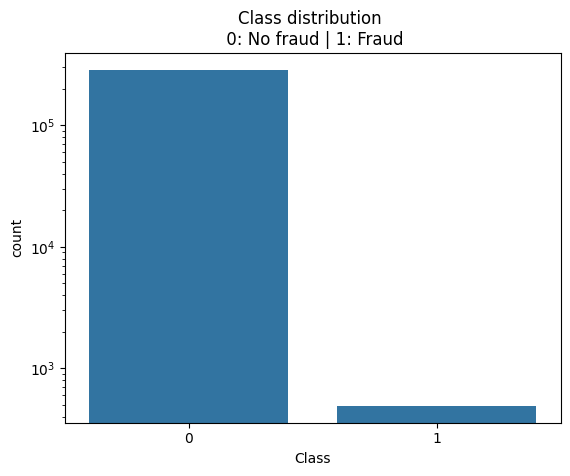

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

counts = data["Class"].value_counts()
print(counts / len(data) * 100) # percentage of fraud and non-fraud transactions
sb.countplot(x="Class",data=data)
plt.title("Class distribution \n 0: No fraud | 1: Fraud")
plt.yscale('log') #to visualize the class imbalance better
plt.show()

In [4]:
#missing values
print("Total missing values:",data.isnull().sum().sum()) 
print("duplicate rows: ",data.duplicated().sum())
print("duplicate rows among fraud transactions: ", data[data["Class"] == 1].duplicated().sum())
print("Min & Max amount: ",data["Amount"].min(), data["Amount"].max())
print("Min & Max time: ",data["Time"].min(), data["Time"].max())

Total missing values: 0
duplicate rows:  1081
duplicate rows among fraud transactions:  19
Min & Max amount:  0.0 25691.16
Min & Max time:  0.0 172792.0


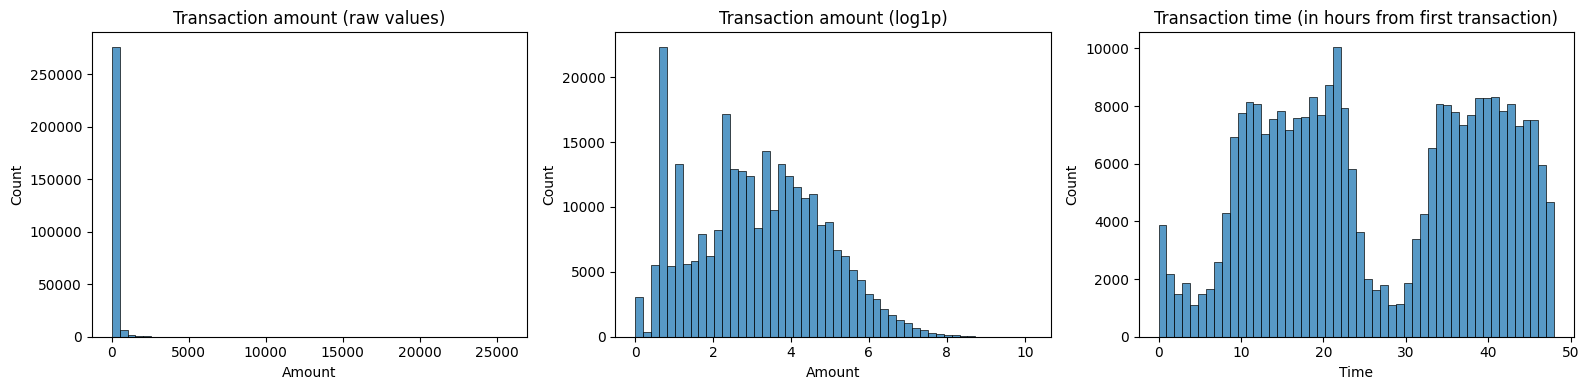

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [8]:
fig,ax = plt.subplots(1,3,figsize=(16,4)) # 1 row, 3 columns grid

sb.histplot(data=data["Amount"],bins=50,ax=ax[0])
ax[0].set_title("Transaction amount (raw values)")

sb.histplot(np.log1p(data["Amount"]),bins=50,ax=ax[1])
ax[1].set_title("Transaction amount (log1p)")

sb.histplot(data = data["Time"] / 3600,bins=50,ax=ax[2])
ax[2].set_title("Transaction time (in hours from first transaction)")

plt.tight_layout()
plt.show()

print(data.groupby("Class")["Amount"].describe())


V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
Name: Class, dtype: float64
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Name: Class, dtype: float64


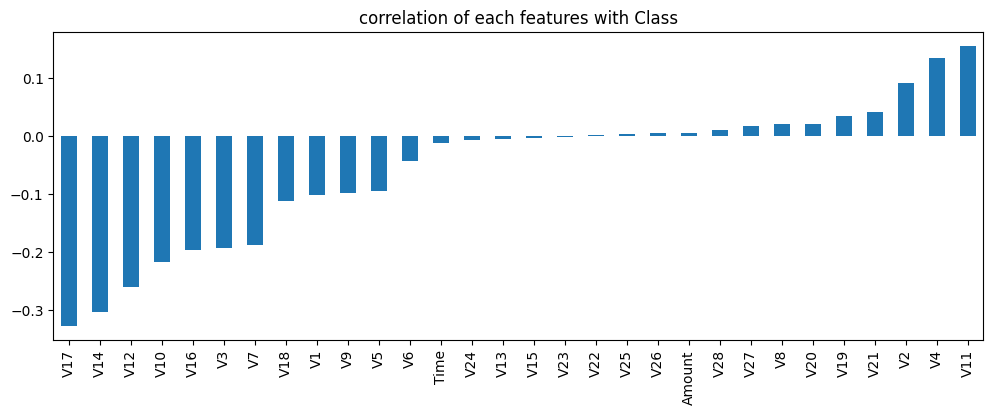

In [22]:
corr = data.corr()["Class"].drop("Class").sort_values() #correlation of all features with "Class"
print(corr.head(10))
print(corr.tail(10))

corr.plot(kind="bar",figsize=(12,4),title="correlation of each features with Class")
plt.show()

## EDA SUMMARY

- **Dataset** : 2,83,807 transactions. 31 columns (Time, V1-V28, Amount, Class)

- **imbalance**: 99.83% of transactions are non-fraud and only about 0.17% is fraud. which shows imbalance

- **Missing values** : No missing values

- **duplicates** : Around 1100 records are redundant. Need to drop in cleaning phase

- **Amount** : Heavily right-skewed

- **Time** : converted from seconds to hours from the first transaction. Contains 48 hours of transactions

- **V1-V28** : Anonymized data. Can't be interpreted directly. V17, V14, V12 shows strong negative correlation

### Next steps:

- Drop duplicate rows

- Bring the values (Amount, Time) into common scale using scalar fit in training data. The test data should be unseen and new

- Use stratified train/test split to evenly spread 0.17% of fraud class data between train & test data

- Handle imbalance with weighing the class & Evaluate with PR-AUC (Precision Recall-Area Under Curve)

